# 생선 길이로 무게 예측

- 회귀(regression)
    - 임의의 어떤 숫자를 예측하는 문제
    - 변수들 사이의 상관관계를 분석하는 방법
 
- KNN회귀
    1. 분류와 똑같이 예측하려는 샘플에 가장 가까운 샘플 k개를 선택
 
    2. k개의 샘플의 종속변수 값의 평균을 구함

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error

# 데이터 준비

In [2]:
df = pd.read_csv("./data/Fish.csv")

In [3]:
# 농어 데이터만 사용
df = df.loc[df["Species"] == "Perch", ["Species", "Length2", "Weight"]]

In [4]:
df.head()

,Species,Length2,Weight
72,Perch,8.4,5.9
73,Perch,13.7,32.0
74,Perch,15.0,40.0
75,Perch,16.2,51.5
76,Perch,17.4,70.0


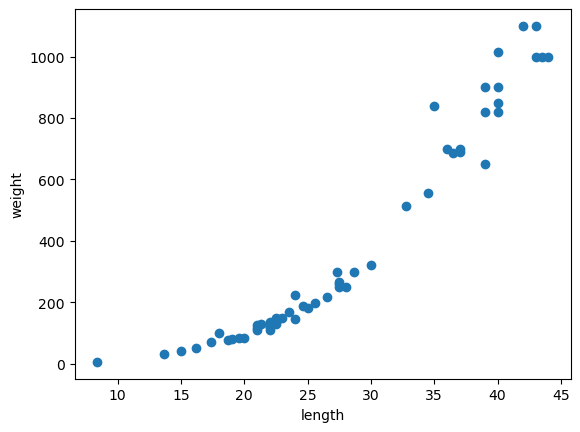

In [5]:
plt.figure()

plt.scatter(df["Length2"], df["Weight"])
plt.xlabel("length")
plt.ylabel("weight")
plt.show()

- 길이가 커짐에 따라 무게가 증가하는 경향이 있음

In [6]:
# 75 : 25 로 데이터 분할
x_train, x_test, y_train, y_test = train_test_split(df["Length2"], df["Weight"],
                                                    test_size = 0.25, random_state = 23)

In [9]:
x_train.shape

(42,)

In [11]:
# 독립변수는 2차원 배열이어야 함
x_train.values

array([19.6, 32.8, 16.2, 30. , 21. , 36. , 27.5, 26.5, 25.6, 42. , 22.5,
       27.5, 40. , 17.4, 28. , 19. , 40. , 13.7, 44. , 40. , 22. , 39. ,
       37. ,  8.4, 18. , 22.7, 21. , 15. , 40. , 18.7, 24. , 24.6, 35. ,
       25. , 21. , 39. , 27.5, 43. , 20. , 36.5, 34.5, 22.5])

In [12]:
x_train = np.reshape(x_train.values, (-1, 1))

In [13]:
x_train.shape

(42, 1)

In [14]:
x_train[:5]

array([[19.6],
       [32.8],
       [16.2],
       [30. ],
       [21. ]])

In [15]:
x_test = np.reshape(x_test.values, (-1, 1))

# 모델 훈련

In [16]:
knr = KNeighborsRegressor()

In [17]:
knr.fit(x_train, y_train)

KNeighborsRegressor()

# 모델 평가

- 결정 계수
    - 계산식
        - 1 - ((sum((타깃 - 예측)^2)) / (sum((타깃 - 타깃평균)^2)))
    
    - 모델의 설명력을 뜻함
 
    - 1에 가까울수록 모델 성능이 좋음

In [18]:
knr.score(x_test, y_test)

0.9885144748807311

- mean_absolute_error
    - 타깃과 예측의 절댓값 오차를 평균하여 반환

In [19]:
# 테스트 세트에 대한 예측
pred = knr.predict(x_test)

In [20]:
pred

array([131. , 831. , 131. , 269. , 248.6, 161.6, 974. , 131. , 974. ,
       138. , 151.6, 749. , 131. , 124. ])

In [21]:
# 테스트 세트에 대한 평균 절댓값 오차를 계산
mae = mean_absolute_error(y_test, pred)

In [22]:
mae

28.514285714285716

In [23]:
pd.DataFrame({"ans" : y_test, "pred" : pred})

,ans,pred
88,130.0,131.0
116,900.0,831.0
86,120.0,131.0
107,300.0,269.0
102,300.0,248.6
96,225.0,161.6
124,1000.0,974.0
90,110.0,131.0
126,1000.0,974.0
94,150.0,138.0


<img src = "./ML_전체이미지/KNN_VS_LINEAR.png">

In [24]:
max(x_train)

array([44.])

In [26]:
knr.predict([[50]])

array([974.])

In [27]:
knr.predict([[60]])

array([974.])

In [28]:
max(y_train)

1100.0

In [29]:
# 50cm 농어의 이웃 찾기
dist, idx = knr.kneighbors([[50]])

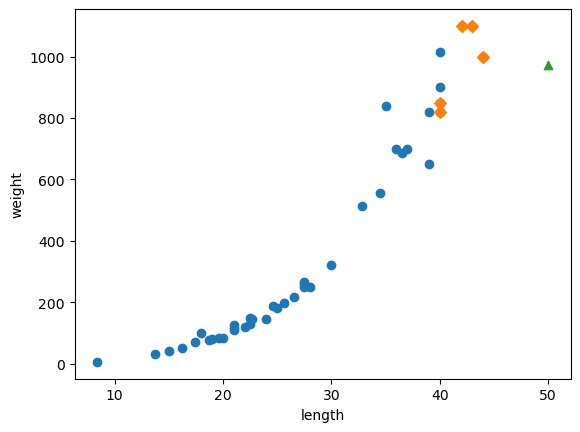

In [30]:
plt.figure()

plt.scatter(x_train, y_train)
plt.scatter(x_train[idx], y_train.iloc[idx.flatten()], marker = "D")
plt.scatter(50, 974, marker = "^")

plt.xlabel("length")
plt.ylabel("weight")
plt.show()